# Playground · Detector de EPP (casco)

Cuaderno de exploración. Acá probamos el modelo **paso a paso**, antes de armar la app.

**Regla:** ejecutá una celda por vez (`Shift + Enter`), leé lo que devuelve y recién después pasá a la siguiente.

## Paso 1 · Preparar y cargar las herramientas

- Borramos la variable que inyecta el antivirus Avast (ver PLAN.md, problema 2).
- Importamos las tres herramientas que vamos a usar.

In [1]:
import os

# Avast agrega esta variable y rompe las conexiones seguras de Python
os.environ.pop("SSLKEYLOGFILE", None)
# Oculta un aviso inofensivo de Hugging Face en Windows
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

from huggingface_hub import hf_hub_download  # descarga archivos de Hugging Face
from ultralytics import YOLO                  # carga y ejecuta modelos YOLO
from PIL import Image                         # abre y muestra imágenes

print("Herramientas listas")

d:\CDEIA\CDEIA II-2026\Técnicas de Procesamiento Digital de Imágenes\TP2\Laboratorio Práctico Modelo de Visión\detector-epp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Herramientas listas


## Paso 2 · Descargar y cargar el modelo 1

`best.pt` es el archivo de **pesos**: los números que el modelo aprendió durante su entrenamiento.
La primera vez se descarga (6 MB); después queda guardado en la computadora.

In [2]:
ruta_pesos = hf_hub_download(
    repo_id="keremberke/yolov8n-hard-hat-detection",  # el repositorio en Hugging Face
    filename="best.pt",                                # el archivo de pesos
)

modelo = YOLO(ruta_pesos)

# ¿Qué clases conoce el modelo? (las definieron quienes etiquetaron el dataset)
print(modelo.names)

{0: 'Hardhat', 1: 'NO-Hardhat'}


## Paso 3 · Abrir una foto de prueba

Antes de ejecutar esta celda, guardá una foto de obreros con casco en la carpeta `pruebas/` con el nombre `foto1.jpg`.

Tamaño (ancho x alto): (5754, 3836)


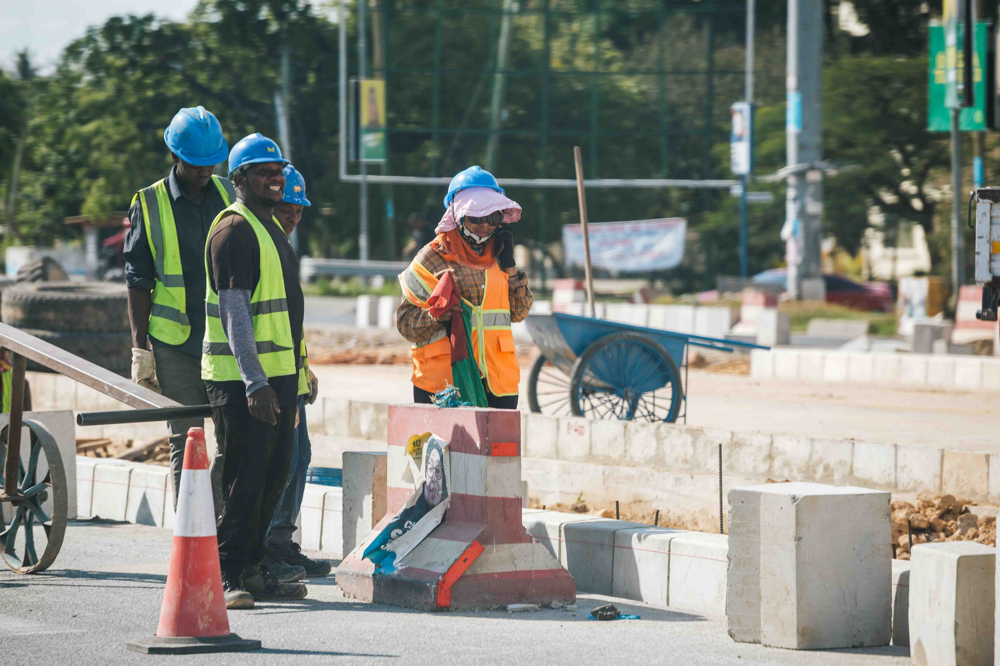

In [3]:
foto = Image.open("pruebas/foto1.jpg")

print("Tamaño (ancho x alto):", foto.size)
foto

## Paso 4 · Pedirle al modelo que detecte

- `conf=0.25` es el **umbral de confianza**: el modelo solo informa detecciones con al menos 25 % de seguridad.
- `imgsz=1280` es el **tamaño de análisis**: YOLO achica la foto hasta que su lado más largo mida esa cantidad de píxeles.
  Por defecto usa 640, pero nuestra foto es muy grande (5754 px) y el casco del obrero del fondo quedaría tan chico que el modelo no lo reconoce.
  En el Paso 6 comparamos los dos tamaños.


0: 864x1280 4 Hardhats, 3733.1ms
Speed: 1487.8ms preprocess, 3733.1ms inference, 727.2ms postprocess per image at shape (1, 3, 864, 1280)


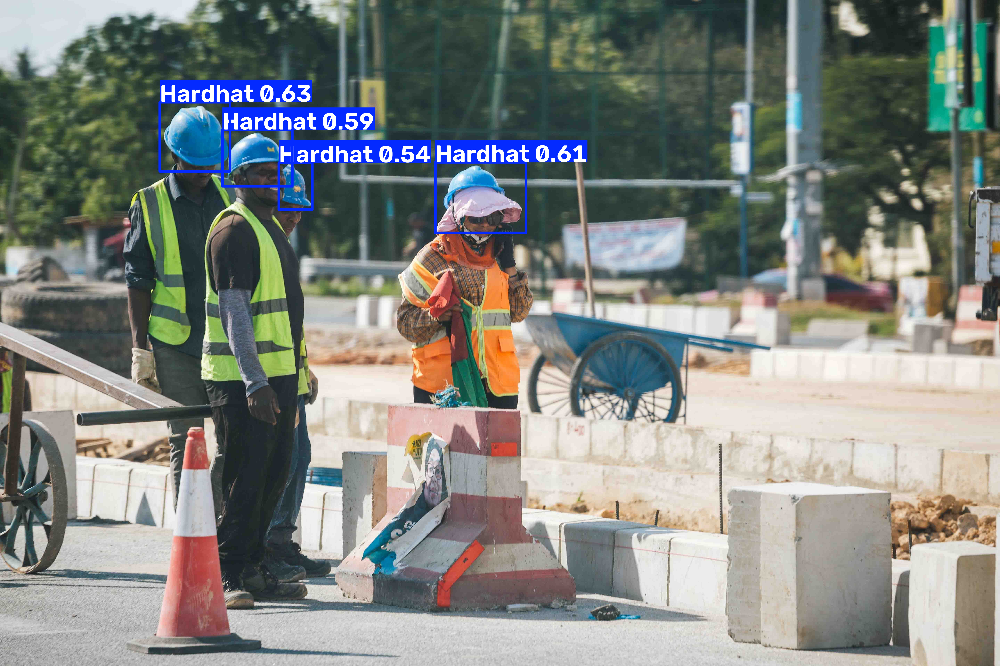

In [4]:
resultados = modelo.predict(foto, conf=0.25, imgsz=1280)
resultado = resultados[0]  # analizamos una sola foto, así que tomamos el primer resultado

# plot() dibuja las cajas. Devuelve los colores en orden BGR; [:, :, ::-1] los pasa a RGB
Image.fromarray(resultado.plot()[:, :, ::-1])

## Paso 5 · Mirar "adentro" de la respuesta

Cada detección tiene tres datos: **qué** es (clase), **cuán seguro** está (confianza) y **dónde** está (caja).

In [5]:
print("Cantidad de detecciones:", len(resultado.boxes))

for caja in resultado.boxes:
    clase = modelo.names[int(caja.cls)]            # número de clase -> nombre
    confianza = float(caja.conf)                   # entre 0 y 1
    x1, y1, x2, y2 = caja.xyxy[0].int().tolist()   # esquinas de la caja, en píxeles
    print(f"{clase:12} confianza {confianza:.0%}  caja ({x1}, {y1}) -> ({x2}, {y2})")

Cantidad de detecciones: 4
Hardhat      confianza 63%  caja (919, 588) -> (1323, 986)
Hardhat      confianza 61%  caja (2504, 934) -> (3026, 1341)
Hardhat      confianza 59%  caja (1280, 748) -> (1681, 1072)
Hardhat      confianza 54%  caja (1604, 937) -> (1796, 1206)


## Paso 6 · ¿Por qué falta un casco? El tamaño de entrada (`imgsz`)

La foto de prueba tiene **4 cascos**, pero con la configuración del Paso 4 el modelo encuentra solo **3**.
El que falta es el del obrero del fondo: está **tapado a medias** y es **chico**.

La causa principal: antes de analizar, YOLO **achica la foto** para que su lado más largo mida `imgsz` píxeles.
El modelo se entrenó con `imgsz=640`, que es el valor por defecto. Primero calculemos cuánto se achica nuestra foto.

In [6]:
ancho, alto = foto.size
lado_mayor = max(ancho, alto)

for imgsz in (640, 1280):
    escala = imgsz / lado_mayor
    print(f"imgsz={imgsz:4}: la foto se reduce {1 / escala:.1f} veces "
          f"-> un casco de 215 x 280 px queda en {215 * escala:.0f} x {280 * escala:.0f} px")

imgsz= 640: la foto se reduce 9.0 veces -> un casco de 215 x 280 px queda en 24 x 31 px
imgsz=1280: la foto se reduce 4.5 veces -> un casco de 215 x 280 px queda en 48 x 62 px


Ahora ejecutamos el modelo **con los dos tamaños** y mostramos los resultados lado a lado.
Para que la comparación sea justa, usamos el mismo umbral (`conf=0.25`) en los dos casos.

--- imgsz=640: 3 detecciones ---
   Hardhat      confianza 92%
   Hardhat      confianza 79%
   Hardhat      confianza 75%
--- imgsz=1280: 4 detecciones ---
   Hardhat      confianza 63%
   Hardhat      confianza 61%
   Hardhat      confianza 59%
   Hardhat      confianza 54%


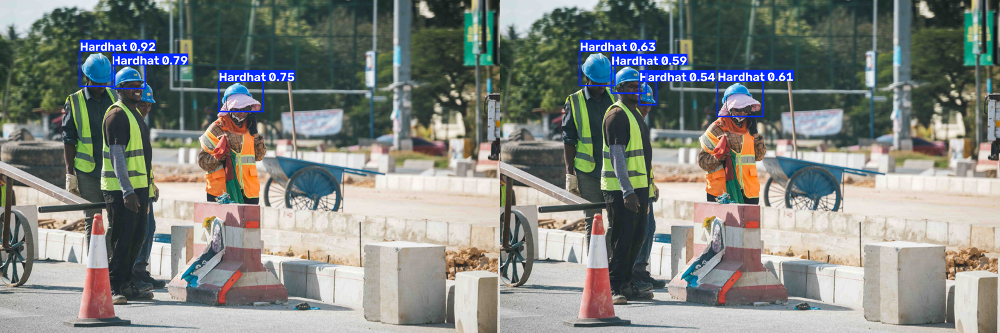

In [7]:
imagenes = []

for imgsz in (640, 1280):
    r = modelo.predict(foto, conf=0.25, imgsz=imgsz, verbose=False)[0]

    print(f"--- imgsz={imgsz}: {len(r.boxes)} detecciones ---")
    for caja in r.boxes:
        clase = modelo.names[int(caja.cls)]
        print(f"   {clase:12} confianza {float(caja.conf):.0%}")

    imagenes.append(Image.fromarray(r.plot()[:, :, ::-1]))

# Pegamos las dos imágenes una al lado de la otra (izquierda: 640, derecha: 1280)
comparacion = Image.new("RGB", (ancho * 2, alto))
comparacion.paste(imagenes[0], (0, 0))
comparacion.paste(imagenes[1], (ancho, 0))
comparacion.resize((1600, int(1600 * alto / (ancho * 2))))  # la achicamos solo para verla en pantalla

### Qué aprendimos

| | `imgsz=640` | `imgsz=1280` |
|---|---|---|
| Cascos detectados | 3 de 4 | **4 de 4** |
| Confianza de los cascos grandes | alta (75 %–92 %) | más baja (59 %–63 %) |
| Confianza del casco del fondo | 8 % (queda descartado) | 54 % |
| Velocidad | más rápido | unas 4 veces más cálculo |

- **Más resolución ayuda con los objetos chicos o lejanos**: el casco del fondo pasa de unos 24 px a unos 48 px y el modelo lo reconoce.
- **No es gratis**: los cascos grandes bajan de confianza, porque el modelo aprendió con imágenes de 640 px y a otra escala los ve distintos. Además, el cálculo es mayor.
- **Bajar el umbral no es la solución**: con `conf=0.05` aparece el casco del fondo, pero también cajas repetidas sobre los otros cascos.
- El modelo es la versión **nano** de YOLOv8 (la más chica). Un modelo más grande o entrenado con más imágenes de personas lejanas debería rendir mejor en estos casos.

## Paso 7 · El problema más grave: gorras y cabezas descubiertas

Con las 17 fotos de prueba (`pruebas/fuentes.md`) apareció un error peor que el casco que faltaba:
el modelo 1 marca **gorras, pañuelos y cabezas descubiertas como "con casco"**.
En una multitud informa 82 % a 88 % de cumplimiento cuando el real ronda el 47 %.

Ningún ajuste de tamaño ni regla sobre las cajas lo corrigió: para el modelo 1, una gorra **es** un casco.
Por eso probamos el **modelo 2** del plan (PLAN.md, sección 3 bis): `luisarizmendi/hardhat-or-hat`.

| | Modelo 1 (Rápido) | Modelo 2 (Preciso) |
|---|---|---|
| Arquitectura | YOLOv8 **n**ano | YOLO11 **x** (extra grande) |
| Peso | 6 MB | 114 MB |
| Clases | `Hardhat`, `NO-Hardhat` | `helmet`, `no_helmet` |

Usamos la versión **v1** del repositorio. La v2 agrega la clase `hat` (gorra), pero en nuestras pruebas dio peores resultados.

In [ ]:
ruta_pesos_2 = hf_hub_download(
    repo_id="luisarizmendi/hardhat-or-hat",
    filename="v1/model/pytorch/best.pt",   # 114 MB: la primera vez tarda en descargarse
)

modelo_2 = YOLO(ruta_pesos_2)

print("Clases del modelo 2:", modelo_2.names)

Ahora analizamos **la misma foto de la multitud** con los dos modelos.
Cada uno usa el tamaño de análisis con el que tuvo menos errores: el modelo 1 analiza con 1280
y el modelo 2 con 640 (es su tamaño de entrenamiento).

In [ ]:
multitud = Image.open("pruebas/pexels-ozkanoztas-38043248.jpg")

# Las clases tienen nombres distintos en cada modelo: las llevamos a "con" y "sin" casco
CON_CASCO = {"Hardhat", "helmet"}

comparacion_modelos = []
for nombre, m, imgsz in [("Modelo 1", modelo, 1280), ("Modelo 2", modelo_2, 640)]:
    r = m.predict(multitud, conf=0.25, imgsz=imgsz, verbose=False)[0]
    clases = [m.names[int(c)] for c in r.boxes.cls]
    con = sum(c in CON_CASCO for c in clases)
    sin = len(clases) - con
    print(f"{nombre}: {con} con casco, {sin} sin casco -> cumplimiento {con / (con + sin):.0%}")
    comparacion_modelos.append(Image.fromarray(r.plot()[:, :, ::-1]))

# Izquierda: modelo 1 · derecha: modelo 2
ancho_m, alto_m = multitud.size
lado_a_lado = Image.new("RGB", (ancho_m * 2, alto_m))
lado_a_lado.paste(comparacion_modelos[0], (0, 0))
lado_a_lado.paste(comparacion_modelos[1], (ancho_m, 0))
lado_a_lado.resize((1600, int(1600 * alto_m / (ancho_m * 2))))

## Paso 8 · Medir los dos modelos con las 17 fotos

Mirar una sola foto no alcanza para elegir un modelo. Medimos los dos con **las 17 fotos de prueba**.

**Error total** = suma, foto por foto, de cuántas cabezas con casco y sin casco de diferencia hay con la realidad
(la realidad la contamos a ojo, ver `pruebas/fuentes.md`). Cuanto más bajo, mejor.

Esta celda tarda uno o dos minutos: el modelo 2 es grande.

In [ ]:
from pathlib import Path

# Realidad contada a ojo: (con casco, sin casco). Las multitudes son aproximadas.
REALIDAD = {
    "foto1": (4, 0), "foto2": (5, 2), "pexels-akoonie": (1, 0), "pexels-cmrcn": (1, 0),
    "pexels-cristian": (1, 0), "pexels-dongfang": (1, 1), "pexels-doruk": (4, 0),
    "pexels-erik": (1, 0), "pexels-hanna": (1, 0), "pexels-imamuddin": (8, 0),
    "pexels-jerome031": (4, 0), "pexels-kalz": (1, 1), "pexels-karanwang": (3, 0),
    "pexels-madknoxxdeluxe": (1, 0), "pexels-ozkanoztas": (9, 10), "pexels-safari": (1, 0),
    "pexels-wal_": (4, 0),
}

for nombre, m, imgsz in [("Modelo 1", modelo, 1280), ("Modelo 2", modelo_2, 640)]:
    error_total, exactas = 0, 0
    for ruta in sorted(Path("pruebas").glob("*.jpg")):
        real = next(v for k, v in REALIDAD.items() if ruta.name.startswith(k))
        r = m.predict(Image.open(ruta), conf=0.25, imgsz=imgsz, verbose=False)[0]
        clases = [m.names[int(c)] for c in r.boxes.cls]
        con = sum(c in CON_CASCO for c in clases)
        sin = len(clases) - con
        error = abs(con - real[0]) + abs(sin - real[1])
        error_total += error
        exactas += error == 0
    print(f"{nombre}: error total {error_total}, conteo exacto en {exactas} de {len(REALIDAD)} fotos")

### Qué aprendimos

| | Modelo 1 (YOLOv8n) | Modelo 2 (YOLO11x) |
|---|:---:|:---:|
| Error total en 17 fotos | 26 (24 con el modo combinado de la app) | **11** |
| Multitud con gorras (real ≈ 47 %) | 86 % | **45 %** (50 % en la app, que además elimina cajas repetidas) |
| Peso | **6 MB** | 114 MB |
| Tiempo por foto (PC sin placa de video) | **menos de 1 s** | unos 2 s |

- **Un modelo más grande y entrenado con otros datos corrigió lo que ningún ajuste pudo.** El modelo 2 aprendió a separar gorras y cabezas descubiertas de los cascos.
- **No hay almuerzo gratis:** es 20 veces más pesado. Por eso la app ofrece los dos: **Preciso** (modelo 2, por defecto) y **Rápido** (modelo 1).
- **Elegimos con datos, no con la ficha del modelo:** la ficha del modelo 2 declaraba una precisión baja y dudosa (mAP50 = 0,567), pero en nuestras fotos fue el mejor.
- Los dos siguen perdiendo **cascos tapados** en multitudes y **personas agachadas**: para eso habría que reentrenar con fotos de ese tipo.

En la versión web, el modelo 2 se comprime de 228 MB a 58 MB (`exportar_onnx.py`) y su error sube a 15. Ver el README.